# cz. II Preprocessing
# Analiza danych Tennessee Eastman Process (TEP)

Projekt z przedmiotu *Eksploracja Danych w Systemach Automatyki*. \
**Autor:** Bartosz Kamieniarz 272402 \
**Wykorzystany zbiór danych:** https://www.kaggle.com/datasets/afrniomelo/tep-csv

Podzbiór jest ten sam co w EDA: klasy `0, 4, 6, 8, 13, 15`, po 30 symulacji.

### 4.1. Analiza jakości danych

Na tym kroku nic nie skalujemy. Sprawdzamy braki, wartości nieskończone, powtórzone klucze (`faultNumber`, `simulationRun`, `sample`), pełną oś czasu i kolumny stałe.


In [10]:
import gc
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(exist_ok=True)

FAULT_NUMBERS = [0, 4, 6, 8, 13, 15]
N_SIMULATIONS = 30
META_COLS = ["faultNumber", "simulationRun", "sample"]


def load_tep_subset(fault_free_path, faulty_path, fault_numbers, n_simulations, chunksize=200_000):
    frames = []
    if 0 in fault_numbers:
        ff = pd.read_csv(fault_free_path)
        frames.append(ff.loc[ff["simulationRun"] <= n_simulations])
        del ff
    selected_faults = [f for f in fault_numbers if f != 0]
    if selected_faults:
        for chunk in pd.read_csv(faulty_path, chunksize=chunksize):
            mask = chunk["faultNumber"].isin(selected_faults) & (chunk["simulationRun"] <= n_simulations)
            filtered = chunk.loc[mask]
            if not filtered.empty:
                frames.append(filtered)
            del chunk, filtered
    df = pd.concat(frames, ignore_index=True)
    del frames
    return df.sort_values(META_COLS).reset_index(drop=True)


def save_latex_table(df, path, caption, label, float_format="%.3f"):
    body = df.to_latex(
        escape=True,
        float_format=float_format,
        column_format="l" + "r" * df.shape[1],
        index=True,
        index_names=False,
    )
    path.write_text(
        "\\begin{table}[ht]\n\\centering\n"
        f"\\caption{{{caption}}}\n\\label{{{label}}}\n\\scriptsize\n"
        f"{body}\\end{{table}}\n",
        encoding="utf-8",
    )
    print(f"LaTeX: {path}")


def quality_checks(df, expected_samples):
    """Jedno przejście po kolumnach, bez kopii całej tabeli."""
    process_cols = [c for c in df.columns if c not in META_COLS]
    n = len(df)
    n_missing = int(df.isna().sum().sum())
    n_inf = 0
    means, stds, nuniques = {}, {}, {}
    for col in process_cols:
        values = df[col].to_numpy()
        n_inf += int(np.isinf(values).sum())
        means[col] = float(values.mean())
        stds[col] = float(values.std(ddof=1))
        nuniques[col] = int(pd.Series(values).nunique(dropna=False))
        del values
    span = df.groupby(["faultNumber", "simulationRun"], sort=False)["sample"].agg(["min", "max", "nunique", "size"])
    complete = (
        (span["min"] == 1)
        & (span["max"] == expected_samples)
        & (span["nunique"] == expected_samples)
        & (span["size"] == expected_samples)
    )
    # Unikalny klucz (awaria, symulacja, próbka) oznacza unikalny wiersz.
    n_dup_keys = int(df.duplicated(META_COLS).sum())
    n_constant = sum((stds[c] == 0) or (nuniques[c] <= 1) for c in process_cols)
    return {
        "Obserwacje": n,
        "Braki": n_missing,
        "Procent braków": 100 * n_missing / df.size,
        "Wartości nieskończone": n_inf,
        "Zduplikowane klucze": n_dup_keys,
        "Przebiegi": len(span),
        "Próbek w przebiegu": expected_samples,
        "Niepełne przebiegi": int((~complete).sum()),
        "Kolumny stałe": n_constant,
        "_mean": pd.Series(means),
        "_std": pd.Series(stds),
        "_nunique": pd.Series(nuniques),
    }


def load_and_check(free_name, faulty_name, expected_samples, label):
    df = load_tep_subset(
        DATA_DIR / free_name,
        DATA_DIR / faulty_name,
        FAULT_NUMBERS,
        N_SIMULATIONS,
    )
    print(f"{label}: {len(df):,} wierszy")
    result = quality_checks(df, expected_samples)
    del df
    gc.collect()
    return result


train_qa = load_and_check(
    "TEP_FaultFree_Training.csv",
    "TEP_Faulty_Training.csv",
    500,
    "Trening",
)
test_qa = load_and_check(
    "TEP_FaultFree_Testing.csv",
    "TEP_Faulty_Testing.csv",
    960,
    "Test",
)


Trening: 90,000 wierszy
Test: 172,800 wierszy


In [11]:
def _as_table(result):
    shown = {}
    for key, value in result.items():
        if key.startswith("_"):
            continue
        shown[key] = f"{value:.2f}" if key == "Procent braków" else int(value)
    return shown


overview = pd.DataFrame({"Treningowy": _as_table(train_qa), "Testowy": _as_table(test_qa)})
overview.index.name = "Kontrola"
save_latex_table(
    overview,
    TABLE_DIR / "quality_overview.tex",
    caption="Kontrola jakości podzbioru treningowego i testowego (klasy 0, 4, 6, 8, 13 i 15, po 30 symulacji).",
    label="tab:quality-overview",
    float_format="%.2f",
)
overview


LaTeX: tables/quality_overview.tex


,Treningowy,Testowy
Kontrola,,
Obserwacje,90000,172800
Braki,0,0
Procent braków,0.00,0.00
Wartości nieskończone,0,0
Zduplikowane klucze,0,0
Przebiegi,180,180
Próbek w przebiegu,500,960
Niepełne przebiegi,0,0
Kolumny stałe,0,0


In [12]:
std = train_qa["_std"]
mean = train_qa["_mean"]
cv = std / mean.abs()
low = pd.DataFrame(
    {
        "Średnia": mean,
        "Odch. std": std,
        "CV": cv,
        "Unikalne": train_qa["_nunique"].astype(int),
    }
).sort_values("CV").head(5)
low.index.name = "Zmienna"
low["Średnia"] = low["Średnia"].map(lambda v: f"{v:.4f}")
low["Odch. std"] = low["Odch. std"].map(lambda v: f"{v:.4f}")
low["CV"] = low["CV"].map(lambda v: f"{v:.6f}")

print(f"Najmniejsze std: {std.idxmin()} = {std.min():.4f} (średnia {mean[std.idxmin()]:.4f})")
print(f"Największe std:  {std.idxmax()} = {std.max():.2f}")
print(f"Największe CV:   {cv.idxmax()} = {cv.max():.3f}")
test_cv = test_qa["_std"] / test_qa["_mean"].abs()
print(f"Najmniejsze CV na teście: {test_cv.idxmin()} = {test_cv.min():.6f}")

save_latex_table(
    low,
    TABLE_DIR / "quality_low_cv.tex",
    caption="Pięć zmiennych o najmniejszej zmienności względnej na zbiorze treningowym. CV to odchylenie standardowe podzielone przez wartość bezwzględną średniej.",
    label="tab:quality-low-cv",
    float_format="%.4f",
)
low


Najmniejsze std: xmeas_37 = 0.0101 (średnia 0.0185)
Największe std:  xmeas_16 = 121.24
Największe CV:   xmv_3 = 0.780
Najmniejsze CV na teście: xmeas_9 = 0.000167
LaTeX: tables/quality_low_cv.tex


,Średnia,Odch. std,CV,Unikalne
Zmienna,,,,
xmeas_9,120.4005,0.0210,0.000175,29
xmeas_21,94.7628,0.4600,0.004854,2858
xmeas_6,42.3293,0.2405,0.005682,1785
xmeas_5,26.9015,0.1995,0.007416,1344
xmeas_40,53.8267,0.6257,0.011624,2962


### 4.2. Wartości odstające

Metoda: płot Tukeya, osobno dla każdej zmiennej. Granice liczymy **tylko na stanie normalnym zbioru treningowego**:

`[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`.

Tymi granicami oznaczamy punkty we wszystkich klasach zbioru treningowego. Punktów nie usuwamy.


In [ ]:
SELECTED = ["xmeas_12", "xmv_7", "xmeas_1", "xmv_10"]


def outlier_report(df):
    """Udział pól poza płotem oraz odsetek dla czterech zmiennych z EDA."""
    cols = [c for c in df.columns if c not in META_COLS]
    normal = df.loc[df["faultNumber"] == 0, cols]
    q1 = normal.quantile(0.25)
    q3 = normal.quantile(0.75)
    iqr = (q3 - q1).replace(0, np.nan)
    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr
    del normal

    summary = []
    selected_rows = []
    for fault, sub in df.groupby("faultNumber"):
        flags = sub[cols].lt(lo) | sub[cols].gt(hi)
        summary.append({
            "Awaria": int(fault),
            "Obserwacje": len(sub),
            "Procent pól poza płotem": round(100 * float(flags.to_numpy().mean()), 2),
        })
        row = {"Awaria": int(fault)}
        for col in SELECTED:
            row[col] = round(100 * float(flags[col].mean()), 2)
        selected_rows.append(row)
        del flags
    by_fault = pd.DataFrame(summary).set_index("Awaria")
    by_var = pd.DataFrame(selected_rows).set_index("Awaria")
    return lo, hi, by_fault, by_var


train = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Training.csv",
    DATA_DIR / "TEP_Faulty_Training.csv",
    FAULT_NUMBERS,
    N_SIMULATIONS,
)
train["faultNumber"] = train["faultNumber"].astype(int)
lo, hi, outliers_train, outliers_selected = outlier_report(train)
del train
gc.collect()

print("Trening, procent pól poza płotem wyznaczonym na stanie normalnym:")
print(outliers_train.to_string())
print()
print("Cztery zmienne z EDA, procent obserwacji poza płotem:")
print(outliers_selected.to_string())

save_latex_table(
    outliers_train,
    TABLE_DIR / "outliers_by_fault.tex",
    caption="Procent pól poza płotem Tukeya. Granice wyznaczono na stanie normalnym zbioru treningowego i zastosowano do wszystkich klas treningowych.",
    label="tab:outliers-by-fault",
    float_format="%.2f",
)
save_latex_table(
    outliers_selected,
    TABLE_DIR / "outliers_selected.tex",
    caption="Procent obserwacji poza płotem Tukeya dla czterech zmiennych wybranych w EDA (zbiór treningowy, granice ze stanu normalnego).",
    label="tab:outliers-selected",
    float_format="%.2f",
)
outliers_train


Trening, procent pól poza płotem wyznaczonym na stanie normalnym:
        Obserwacje  Procent pól poza płotem
Awaria                                     
0            15000                     0.83
4            15000                     2.64
6            15000                    54.29
8            15000                    32.26
13           15000                    32.43
15           15000                     0.88

Cztery zmienne z EDA, procent obserwacji poza płotem:
        xmeas_12  xmv_7  xmeas_1  xmv_10
Awaria                                  
0           0.53   0.53     1.04    0.87
4           0.53   0.53     1.04   96.03
6           0.19   0.19    96.00   82.97
8           0.61   0.61    66.93   14.81
13          0.61   0.61    32.69   17.43
15          0.55   0.55     1.09    0.85
LaTeX: tables/outliers_by_fault.tex
LaTeX: tables/outliers_selected.tex


,Obserwacje,Procent pól poza płotem
Awaria,,
0,15000,0.83
4,15000,2.64
6,15000,54.29
8,15000,32.26
13,15000,32.43
15,15000,0.88


### 4.3. Standaryzacja


Skalujemy tylko 52 zmienne procesowe. `faultNumber`, `simulationRun` i `sample` zostają bez zmian.

`StandardScaler` liczy średnią i odchylenie na treningu. Test jest przekształcany tymi samymi liczbami.


In [ ]:
from sklearn.preprocessing import StandardScaler

train = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Training.csv",
    DATA_DIR / "TEP_Faulty_Training.csv",
    FAULT_NUMBERS,
    N_SIMULATIONS,
)
cols = [c for c in train.columns if c not in META_COLS]
scaler = StandardScaler()
scaler.fit(train[cols])

rows = []
for col in SELECTED:
    j = cols.index(col)
    z = (train[col].to_numpy() - scaler.mean_[j]) / scaler.scale_[j]
    rows.append({
        "Zmienna": col,
        "Średnia przed": train[col].mean(),
        "Std przed": train[col].std(ddof=0),
        "Średnia train po": z.mean(),
        "Std train po": z.std(ddof=0),
    })
    del z
train_scaled = pd.DataFrame(rows).set_index("Zmienna")
# kontrola wszystkich 52 kolumn, bez trzymania macierzy po skalowaniu
max_abs_mean = 0.0
for j, col in enumerate(cols):
    z = (train[col].to_numpy() - scaler.mean_[j]) / scaler.scale_[j]
    max_abs_mean = max(max_abs_mean, abs(float(z.mean())))
    del z
print(f"Trening po standaryzacji, największa |średnia| spośród 52 zmiennych: {max_abs_mean:.2e}")
del train
gc.collect()

test_std = {}
test = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Testing.csv",
    DATA_DIR / "TEP_Faulty_Testing.csv",
    FAULT_NUMBERS,
    N_SIMULATIONS,
)
for col in SELECTED:
    j = cols.index(col)
    z = (test[col].to_numpy() - scaler.mean_[j]) / scaler.scale_[j]
    train_scaled.loc[col, "Średnia test po"] = z.mean()
    train_scaled.loc[col, "Std test po"] = z.std(ddof=0)
    test_std[col] = float(test[col].std(ddof=0))
    del z
del test
gc.collect()

scale_table = train_scaled.round(4)
print(scale_table.to_string())
save_latex_table(
    scale_table,
    TABLE_DIR / "standardization_selected.tex",
    caption="Standaryzacja czterech zmiennych. Średnia i odchylenie pochodzą z całego zbioru treningowego (52 zmienne procesowe) i zostały zastosowane do zbioru testowego.",
    label="tab:standardization",
    float_format="%.4f",
)
scale_table


Trening po standaryzacji, największa |średnia| spośród 52 zmiennych: 9.86e-14
          Średnia przed  Std przed  Średnia train po  Std train po  Średnia test po  Std test po
Zmienna                                                                                         
xmeas_12        50.0317     0.9486              -0.0           1.0           0.0095       1.0088
xmv_7           38.1933     2.7915               0.0           1.0           0.0095       1.0088
xmeas_1          0.2112     0.1263              -0.0           1.0           0.0483       0.9703
xmv_10          43.7877    15.9532               0.0           1.0          -0.0679       1.0261
LaTeX: tables/standardization_selected.tex


,Średnia przed,Std przed,Średnia train po,Std train po,Średnia test po,Std test po
Zmienna,,,,,,
xmeas_12,50.0317,0.9486,-0.0,1.0,0.0095,1.0088
xmv_7,38.1933,2.7915,0.0,1.0,0.0095,1.0088
xmeas_1,0.2112,0.1263,-0.0,1.0,0.0483,0.9703
xmv_10,43.7877,15.9532,0.0,1.0,-0.0679,1.0261


### 4.4. Parametry przeniesione na test

Parametry preprocessingu to średnia i odchylenie zapisane w `scaler.mean_` oraz `scaler.scale_`.
`fit` był wywołany tylko na treningu. Test liczy się wzorem

`(x - średnia_treningu) / odchylenie_treningu`.

Średnia i odchylenie testu w tabeli to wartości, które scaler zapisałby, gdyby dopasować go od nowa do testu. Różnią się od liczb użytych ze treningu, więc test nie wszedł do wyznaczenia parametrów.


In [ ]:
rows = []
for col in SELECTED:
    j = cols.index(col)
    mu = float(scaler.mean_[j])
    sigma = float(scaler.scale_[j])
    z_test = float(scale_table.loc[col, "Średnia test po"])
    mu_test = mu + z_test * sigma
    rows.append({
        "Zmienna": col,
        "Średnia użyta": mu,
        "Odchylenie użyte": sigma,
        "Średnia testu": mu_test,
        "Odchylenie testu": test_std[col],
    })

params = pd.DataFrame(rows).set_index("Zmienna").round(4)
params["Różnica średniej"] = (params["Średnia testu"] - params["Średnia użyta"]).round(4)
params["Różnica odchylenia"] = (params["Odchylenie testu"] - params["Odchylenie użyte"]).round(4)
print(f"Liczba parametrów: {len(cols)} średnich i {len(cols)} odchyleń, fit tylko na treningu.")
print(params.to_string())

save_latex_table(
    params,
    TABLE_DIR / "scaler_params_selected.tex",
    caption="Parametry standaryzacji wyznaczone na zbiorze treningowym i użyte do zbioru testowego. Średnia i odchylenie testu to wartości, które dałoby ponowne dopasowanie scalera do testu. Obie różnice liczone są jako test minus liczba użyta z treningu.",
    label="tab:scaler-params",
    float_format="%.4f",
)

all_params = pd.DataFrame({"zmienna": cols, "srednia_trening": scaler.mean_, "odchylenie_trening": scaler.scale_})
all_params.to_csv(TABLE_DIR / "scaler_params_train.csv", index=False)
print(f"Zapisano {len(all_params)} par parametrów: {TABLE_DIR / 'scaler_params_train.csv'}")
params


Liczba parametrów: 52 średnich i 52 odchyleń, fit tylko na treningu.
          Średnia użyta  Odchylenie użyte  Średnia testu  Odchylenie testu  Różnica średniej  Różnica odchylenia
Zmienna                                                                                                         
xmeas_12        50.0317            0.9486        50.0407            0.9569            0.0090              0.0083
xmv_7           38.1933            2.7915        38.2198            2.8161            0.0265              0.0246
xmeas_1          0.2112            0.1263         0.2173            0.1226            0.0061             -0.0037
xmv_10          43.7877           15.9532        42.7045           16.3696           -1.0832              0.4164
LaTeX: tables/scaler_params_selected.tex
Zapisano 52 par parametrów: tables/scaler_params_train.csv


,Średnia użyta,Odchylenie użyte,Średnia testu,Odchylenie testu,Różnica średniej,Różnica odchylenia
Zmienna,,,,,,
xmeas_12,50.0317,0.9486,50.0407,0.9569,0.0090,0.0083
xmv_7,38.1933,2.7915,38.2198,2.8161,0.0265,0.0246
xmeas_1,0.2112,0.1263,0.2173,0.1226,0.0061,-0.0037
xmv_10,43.7877,15.9532,42.7045,16.3696,-1.0832,0.4164



### 4.6. Wpływ na dane

Przed skalowaniem kilka zmiennych o dużym odchyleniu trzyma prawie całą sumę wariancji.
Po standaryzacji każda z 52 zmiennych ma wariancję 1, więc każda ma udział 1/52.
Korelacja między zmiennymi zostaje ta sama: od każdej odejmuje się stałą i dzieli przez stałą.


In [ ]:
share = pd.read_csv(TABLE_DIR / "scaler_params_train.csv")
share["var"] = share["odchylenie_trening"] ** 2
total = share["var"].sum()
share["udzial"] = 100 * share["var"] / total
after = 100 / len(share)

top = share.nlargest(5, "udzial")
rows = []
for _, row in top.iterrows():
    rows.append({
        "Zmienna": row["zmienna"],
        "Odchylenie": f"{row['odchylenie_trening']:.2f}",
        "Udział przed [%]": f"{row['udzial']:.2f}",
        "Udział po [%]": f"{after:.2f}",
    })
impact = pd.DataFrame(rows).set_index("Zmienna")

print(f"Pięć największych: przed {top['udzial'].sum():.2f}%, po {5 * after:.2f}%")
for name in ["xmv_10", "xmeas_1", "xmeas_37"]:
    part = float(share.loc[share["zmienna"] == name, "udzial"].iloc[0])
    print(f"{name}: przed {part:.4f}%, po {after:.2f}%")

save_latex_table(
    impact,
    TABLE_DIR / "preprocessing_impact.tex",
    caption="Udział pięciu zmiennych o największej wariancji w sumie wariancji treningu, przed standaryzacją i po niej",
    label="tab:preprocessing-impact",
    float_format="%.2f",
)
impact


Pięć największych: przed 93.09%, po 9.62%
xmv_10: przed 0.3958%, po 1.92%
xmeas_1: przed 0.0000%, po 1.92%
xmeas_37: przed 0.0000%, po 1.92%
LaTeX: tables/preprocessing_impact.tex


,Odchylenie,Udział przed [%],Udział po [%]
Zmienna,,,
xmeas_16,121.24,22.86,1.92
xmeas_3,117.61,21.51,1.92
xmeas_7,106.39,17.60,1.92
xmeas_13,104.02,16.83,1.92
xmeas_19,95.84,14.28,1.92


### 4.7. Standaryzacja i normalizacja

Normalizacja rozciąga każdą zmienną na przedział od 0 do 1: `(x - min) / (max - min)`. Minimum i maksimum biorę z całego treningu, tak jak średnią i odchylenie przy standaryzacji.



In [ ]:
train = load_tep_subset(
    DATA_DIR / "TEP_FaultFree_Training.csv",
    DATA_DIR / "TEP_Faulty_Training.csv",
    FAULT_NUMBERS,
    N_SIMULATIONS,
)
cols = [c for c in train.columns if c not in META_COLS]
values = train[cols].to_numpy(dtype=float)
mu = values.mean(axis=0)
sigma = values.std(axis=0, ddof=0)
xmin = values.min(axis=0)
xmax = values.max(axis=0)
span = xmax - xmin
normal_mask = train["faultNumber"].to_numpy() == 0

rows = []
for name in SELECTED:
    j = cols.index(name)
    normal = values[normal_mask, j]
    rows.append({
        "Zmienna": name,
        "Std surowe": sigma[j],
        "Std standaryzacja": 1.0,
        "Std normalizacja": sigma[j] / span[j],
        "Zakres normalny [%]": 100 * (normal.max() - normal.min()) / span[j],
    })
scale_compare = pd.DataFrame(rows).set_index("Zmienna").round(2)

var_mm = (sigma / span) ** 2
share_mm = 100 * var_mm / var_mm.sum()
top5_mm = float(np.sort(share_mm)[-5:].sum())
print(f"Pięć największych udziałów wariancji po normalizacji: {top5_mm:.1f}%")

def _block(fault, sim):
    sub = train[(train["faultNumber"] == fault) & (train["simulationRun"] == sim)]
    sub = sub.sort_values("sample")
    return sub[cols].to_numpy(dtype=float)

def _mean_distance(a, b):
    diff = a - b
    raw = np.sqrt((diff ** 2).sum(axis=1)).mean()
    z = np.sqrt(((diff / sigma) ** 2).sum(axis=1)).mean()
    mm = np.sqrt(((diff / span) ** 2).sum(axis=1)).mean()
    return np.array([raw, z, mm])

sum_normal = np.zeros(3)
sums = {fault: np.zeros(3) for fault in [4, 6, 8, 13, 15]}
for sim in range(1, N_SIMULATIONS + 1):
    ref = _block(0, sim)
    nxt = _block(0, 1 if sim == N_SIMULATIONS else sim + 1)
    sum_normal += _mean_distance(ref, nxt)
    for fault in sums:
        sums[fault] += _mean_distance(ref, _block(fault, sim))

dist_rows = [{
    "Stan": "Inna normalna",
    "Surowa": 1.0,
    "Standaryzacja": 1.0,
    "Normalizacja": 1.0,
}]
for fault in [4, 6, 8, 13, 15]:
    ratio = (sums[fault] / N_SIMULATIONS) / (sum_normal / N_SIMULATIONS)
    dist_rows.append({
        "Stan": f"Awaria {fault}",
        "Surowa": ratio[0],
        "Standaryzacja": ratio[1],
        "Normalizacja": ratio[2],
    })
distances = pd.DataFrame(dist_rows).set_index("Stan").round(2)

del train, values
gc.collect()

save_latex_table(
    scale_compare,
    TABLE_DIR / "scale_compare_selected.tex",
    caption="Cztery zmienne z EDA po standaryzacji i po normalizacji do przedziału [0, 1]. Odchylenia są liczone na całym treningu. Zakres normalny to szerokość stanu normalnego jako procent zakresu całego treningu.",
    label="tab:scale-compare",
    float_format="%.2f",
)
save_latex_table(
    distances,
    TABLE_DIR / "scale_distances.tex",
    caption="Odległość od stanu normalnego podzielona przez odległość między dwiema symulacjami normalnymi. Średnia z 30 symulacji, po 500 próbek, na 52 zmiennych. Liczba 1 oznacza dystans taki jak między dwiema symulacjami normalnymi.",
    label="tab:scale-distances",
    float_format="%.2f",
)
print(scale_compare.to_string())
print(distances.to_string())
distances


Pięć największych udziałów wariancji po normalizacji: 24.9%
LaTeX: tables/scale_compare_selected.tex
LaTeX: tables/scale_distances.tex
          Std surowe  Std standaryzacja  Std normalizacja  Zakres normalny [%]
Zmienna                                                                       
xmeas_12        0.95                1.0              0.13                96.54
xmv_7           2.79                1.0              0.13                96.52
xmeas_1         0.13                1.0              0.15                26.63
xmv_10         15.95                1.0              0.16                 4.51
               Surowa  Standaryzacja  Normalizacja
Stan                                              
Inna normalna    1.00           1.00          1.00
Awaria 4         0.05           0.08          0.08
Awaria 6         7.54           2.30          3.35
Awaria 8         1.73           0.90          0.98
Awaria 13        2.90           1.00          1.15
Awaria 15        0.06           0.

,Surowa,Standaryzacja,Normalizacja
Stan,,,
Inna normalna,1.00,1.00,1.00
Awaria 4,0.05,0.08,0.08
Awaria 6,7.54,2.30,3.35
Awaria 8,1.73,0.90,0.98
Awaria 13,2.90,1.00,1.15
Awaria 15,0.06,0.05,0.04


Zapisano: figures/scale_distances.png


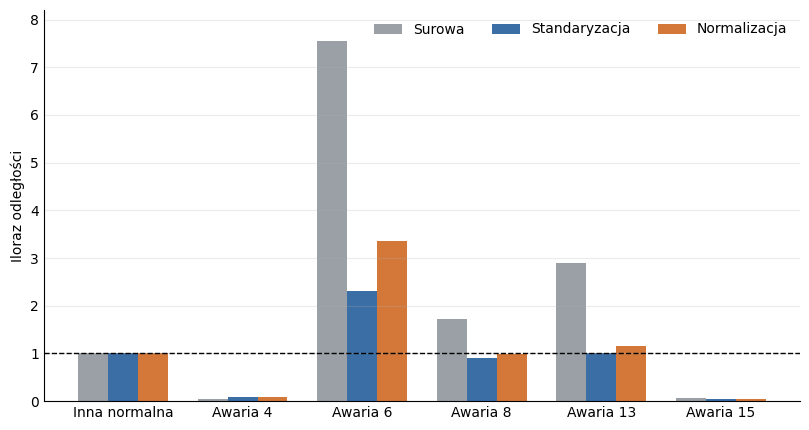

In [35]:
import matplotlib.pyplot as plt

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8.2, 4.4))
x = np.arange(len(distances))
width = 0.25
ax.bar(x - width, distances["Surowa"], width, label="Surowa", color="#9aa0a6")
ax.bar(x, distances["Standaryzacja"], width, label="Standaryzacja", color="#3b6ea5")
ax.bar(x + width, distances["Normalizacja"], width, label="Normalizacja", color="#d4783a")
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(distances.index)
ax.set_ylabel("Iloraz odległości")
ax.set_ylim(0, 8.2)
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(True, axis="y", alpha=0.25)
ax.tick_params(length=0)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig_path = FIG_DIR / "scale_distances.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Zapisano: {fig_path}")
plt.show()
